<a href="https://colab.research.google.com/github/er1cbrown/BiostatsPython/blob/main/Senior_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Senior Project

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load the dataset from a CSV file.
df = pd.read_csv("players_data.csv")

# Inspect the columns to know which one holds the injury description.
print(df.columns)

df.head()


Index(['Name', 'Seasons Played', 'Height', 'Weight', 'Position', 'Injury Date',
       'Injury Type', 'Injury Details'],
      dtype='object')


,Name,Seasons Played,Height,Weight,Position,Injury Date,Injury Type,Injury Details
0,Trey Lance,4,"6'4""",226,QB,"Sep 18, 2022",Pedal Ankle Dislocation,Lance's injury came on a zone-read run.
1,Trey Lance,4,"6'4""",226,QB,"Sep 18, 2022",Pedal Ankle Fracture,Lance's injury came on a zone-read run.
2,Trey Lance,4,"6'4""",226,QB,"Oct 10, 2021",Knee Strain Grade 1,Lance suffered a left knee sprain in the 49ers...
3,Trey Lance,4,"6'4""",226,QB,"Aug 29, 2021",Hand Finger Fracture,Lance suffered a finger injury during the pres...
4,Trey Lance,4,"6'4""",226,QB,"Feb 15, 2020",Knee Meniscus Trim,Trey Lance used crutches following a medical p...


InjuryClass
Pedal       480
Knee        357
Thigh       219
Head        209
Shoulder    192
Inguinal    125
Leg         110
Hand         97
Chest        96
Back         48
Arm          34
Cervical     29
Abdomen      27
Spine         1
Name: count, dtype: int64


/tmp/ipykernel_194143/2170168110.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=injury_counts.index, y=injury_counts.values, palette="viridis")


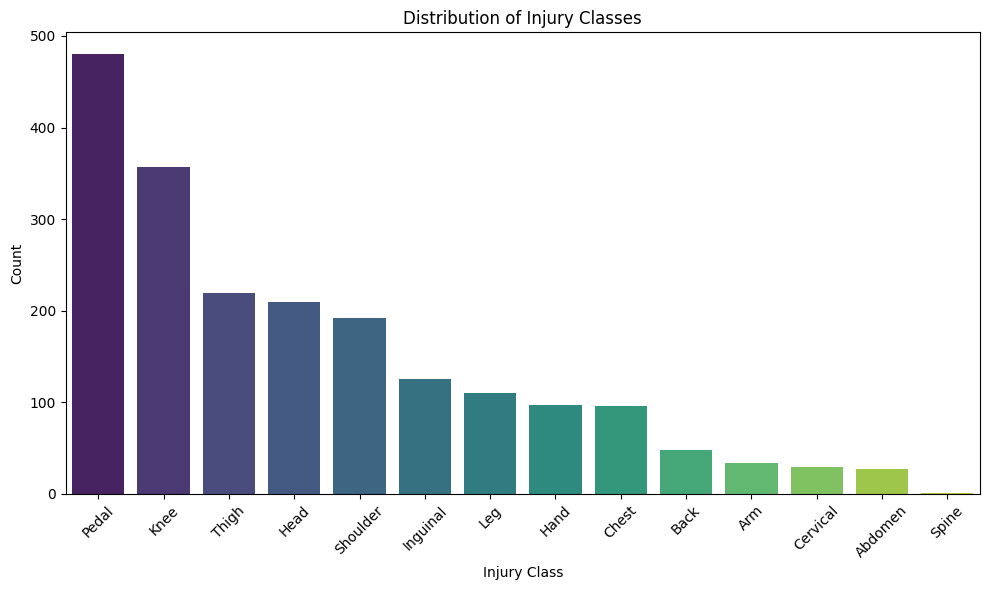

In [ ]:
# Step 2: Group the injuries.
# This example assumes you have a column named 'Injury' with text descriptions.
# A simple approach is to take the first word as the injury type.
df['InjuryClass'] = df['Injury Type'].str.split().str[0]

# def group_injury(injury_text):
#     if pd.isnull(injury_text):
#         return "Unknown"
#     injury_text = injury_text.lower()
#     if "sprain" in injury_text:
#         return "Sprain"
#     elif "tear" in injury_text:
#         return "Tear"
#     elif "concussion" in injury_text:
#         return "Concussion"
#     elif "fracture" in injury_text:
#         return "Fracture"
#     elif "bruise" in injury_text:
#         return "Bruise"
#     else:
#         return "Other"

# Uncomment below if you prefer custom grouping:
# df['InjuryClass'] = df['Injury'].apply(group_injury)

# Step 3: Count the number of injuries per group.
injury_counts = df['InjuryClass'].value_counts()
print(injury_counts)

# Step 4: Plot a bar plot (histogram) of the injury classes.
plt.figure(figsize=(10,6))
sns.barplot(x=injury_counts.index, y=injury_counts.values, palette="viridis")
plt.xlabel("Injury Class")
plt.ylabel("Count")
plt.title("Distribution of Injury Classes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_194143/118217736.py:95: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=injury_counts.index, y=injury_counts.values, palette="viridis")


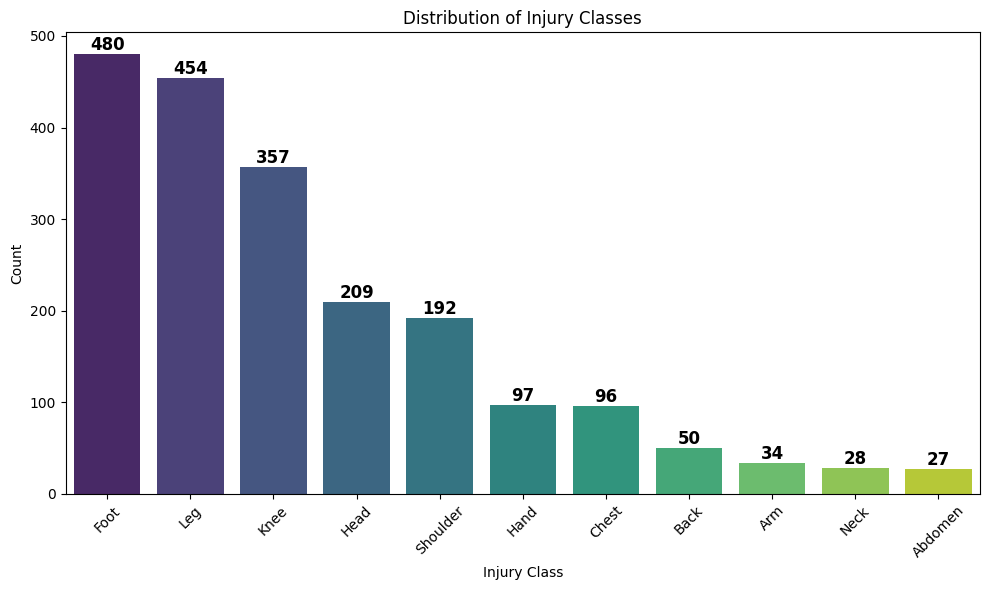

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

# -------------------------------------------------
# 1. LOAD & CLEAN DATA
# -------------------------------------------------
# Load the dataset
df = pd.read_csv("players_data.csv")

# Ensure correct column names
df.rename(columns=lambda x: x.strip(), inplace=True)  # Remove any accidental spaces

# -------------------------------------------------
# 2. PREPROCESSING: INJURY CATEGORIZATION
# -------------------------------------------------

# # Define common injury keywords for grouping
# injury_mapping = {
#     "Knee": ["Knee", "ACL", "MCL", "Patella", "Meniscus"],
#     "Head": ["Concussion", "Head"],
#     "Shoulder": ["Shoulder", "Rotator", "AC", "Labrum", "Pectoral"],
#     "Leg": ["Calf", "Hamstring", "Quadriceps", "Thigh", "Leg", "Inguinal"],
#     "Hip": ["Hip", "Pelvis", "Groin"],
#     "Foot": ["Ankle", "Toe", "Foot", "Achilles", "Heel", "Lisfranc"],
#     "Arm": ["Elbow", "Forearm", "Bicep", "Triceps", "Arm"],
#     "Hand": ["Finger", "Wrist", "Hand"],
#     "Back": ["Back", "Spine", "Disc", "Herniated"],
#     "Neck": ["Neck", "Cervical", "Whiplash"],
#     "Chest": ["Chest", "Ribs", "Sternum"],
#     "Abdomen": ["Abdomen", "Groin"]
# }

injury_mapping = {
    "Knee": ["Knee", "ACL", "MCL", "Patella", "Meniscus"],
    "Head": ["Concussion", "Head"],
    "Shoulder": ["Shoulder", "Rotator", "AC"],
    "Leg": ["Calf", "Hamstring", "Quadriceps", "Thigh", "Leg", "Inguinal"],
    "Foot": ["Ankle", "Toe", "Foot", "Achilles", "Heel", "Lisfranc"],
    "Arm": ["Elbow", "Forearm", "Bicep", "Triceps", "Arm"],
    "Hand": ["Finger", "Wrist", "Hand"],
    "Back": ["Back", "Spine"],
    "Neck": ["Neck", "Cervical"],
    "Chest": ["Chest", ],
    "Abdomen": ["Abdomen",]
}

# Function to categorize injuries based on keywords
# def categorize_injury(injury_text):
#     # print(injury_text)
#     if pd.isna(injury_text):
#         return "Other"
#     for category, keywords in injury_mapping.items():
#         if any(re.search(rf'\b{kw}\b', injury_text, re.IGNORECASE) for kw in keywords):
#             return category
#     return "Other"

# # Apply categorization
# df['InjuryGroup'] = df['Injury Type'].apply(categorize_injury)

# Create a list to store injury descriptions that fall under "Other"
other_injuries = []

# Modified function to categorize injuries and store "Other" cases
def categorize_injury(injury_text):
    if pd.isna(injury_text):
        return "Other"
    for category, keywords in injury_mapping.items():
        if any(re.search(rf'\b{kw}\b', injury_text, re.IGNORECASE) for kw in keywords):
            return category
    other_injuries.append(injury_text)  # Store unclassified injuries
    return "Other"

# Apply categorization
df['InjuryGroup'] = df['Injury Type'].apply(categorize_injury)

# Print unique 'Other' injuries and their counts
# print("\n=== List of Injuries Categorized as 'Other' ===")
# print(pd.Series(other_injuries).value_counts())
# Step 3: Count and Select Top 4 Injury Groups
injury_counts = df['InjuryGroup'].value_counts()
top_4_injuries = injury_counts.head(4).index  # Select top 4 most common injuries

# Filter dataset to only include the top 4 injuries
df_filtered = df[df['InjuryGroup'].isin(top_4_injuries)].copy()

# Plot a histogram of injury classes with count labels
plt.figure(figsize=(10,6))
ax = sns.barplot(x=injury_counts.index, y=injury_counts.values, palette="viridis")

# Add count values on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=12, fontweight='bold', color='black')

# Set labels and title
plt.xlabel("Injury Class")
plt.ylabel("Count")
plt.title("Distribution of Injury Classes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [ ]:
import pandas as pd
import re
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report

# Load dataset
df = pd.read_csv("players_data.csv")

# Ensure correct column names
df.rename(columns=lambda x: x.strip(), inplace=True)

# Injury categorization mapping
injury_mapping = {
    "Knee": ["Knee", "ACL", "MCL", "Patella", "Meniscus"],
    "Head": ["Concussion", "Head"],
    "Shoulder": ["Shoulder", "Rotator", "AC"],
    "Leg": ["Calf", "Hamstring", "Quadriceps", "Thigh", "Leg", "Inguinal"],
    "Foot": ["Ankle", "Toe", "Foot", "Achilles", "Heel", "Lisfranc"],
    "Arm": ["Elbow", "Forearm", "Bicep", "Triceps", "Arm"],
    "Hand": ["Finger", "Wrist", "Hand"],
    "Back": ["Back", "Spine"],
    "Neck": ["Neck", "Cervical"],
    "Chest": ["Chest"],
    "Abdomen": ["Abdomen"]
}

# Function to categorize injuries
def categorize_injury(injury_text):
    if pd.isna(injury_text):
        return "Other"
    for category, keywords in injury_mapping.items():
        if any(re.search(rf'\b{kw}\b', injury_text, re.IGNORECASE) for kw in keywords):
            return category
    return "Other"

# Apply injury categorization
df['InjuryGroup'] = df['Injury Type'].apply(categorize_injury)

# Select top 4 injury categories
injury_counts = df['InjuryGroup'].value_counts()
top_4_injuries = injury_counts.head(4).index
df_filtered = df[df['InjuryGroup'].isin(top_4_injuries)].copy()

# Convert height from feet'inch'' to cm
def convert_height(height_str):
    match = re.match(r"(\d+)'(\d+)\"", str(height_str))
    if match:
        feet = int(match.group(1))
        inches = int(match.group(2))
        return feet * 12 + inches
    return None

df_filtered['Height'] = df_filtered['Height'].apply(convert_height)
df_filtered['Height_cm'] = df_filtered['Height'] * 2.54
df_filtered.dropna(subset=['Height_cm'], inplace=True)  # Drop rows with missing height

# One-hot encode player positions
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded_positions = encoder.fit_transform(df_filtered[['Position']])
encoded_pos_cols = encoder.get_feature_names_out(['Position'])
df_positions = pd.DataFrame(encoded_positions, columns=encoded_pos_cols, index=df_filtered.index)

# Combine numeric features + encoded positions
feature_cols = ['Seasons Played', 'Height_cm', 'Weight']
X = pd.concat([df_filtered[feature_cols], df_positions], axis=1)

# Encode the target variable (InjuryGroup)
label_encoder = LabelEncoder()
df_filtered['InjuryGroup'] = label_encoder.fit_transform(df_filtered['InjuryGroup'])
y = df_filtered['InjuryGroup']

# Ensure PlayerName column is correct
df_filtered.rename(columns={"Name": "PlayerName"}, inplace=True)

# Train/Test split by player to avoid data leakage
groups = df_filtered['PlayerName']
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Hyperparameter grid for tuning
param_grid = {
    'n_estimators': [50, 80, 110],
    # 'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [2, 5, 10, 15],
    # 'subsample': [0.8, 1.0],
    # 'min_samples_split': [2, 5, 10]
}

# Nested Cross-Validation: Outer 5-fold CV, Inner 2-fold GridSearchCV
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

# Initialize Gradient Boosting Classifier
gbt = GradientBoostingClassifier(random_state=42)

# GridSearch with nested cross-validation
grid_search = GridSearchCV(gbt, param_grid, cv=inner_cv, scoring='accuracy', n_jobs=-1, verbose=1)
nested_scores = cross_val_score(grid_search, X, y, cv=outer_cv, scoring='accuracy')

# Train final model using best parameters
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

# Make predictions and evaluate
y_pred = best_model.predict(X_test)
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)

# Print classification report
print("\n=== Classification Report ===")
print(report)


Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits

=== Classification Report ===
              precision    recall  f1-score   support

        Foot       0.40      0.47      0.43       109
        Head       0.00      0.00      0.00        42
        Knee       0.24      0.12      0.16        75
         Leg       0.30      0.50      0.37        82

    accuracy                           0.33       308
   macro avg       0.23      0.27      0.24       308
weighted avg       0.28      0.33      0.29       308



In [ ]:
# Predict and evaluate
y_pred = best_model.predict(X_test)

# Compute AUC Score
y_pred_probs = best_model.predict_proba(X_test)
auc_score = roc_auc_score(pd.get_dummies(y_test), y_pred_probs, multi_class="ovr")

# Display AUC Score
auc_score

0.5490619807820173

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Define hyperparameter grid for Random Forest
rf_param_grid = {
    'n_estimators': [50, 100, 150],  # Number of trees
    'max_depth': [None, 10, 20],  # Maximum depth of trees
    # 'min_samples_split': [2, 5, 10],  # Minimum samples to split a node
    # 'min_samples_leaf': [1, 2, 4]  # Minimum samples per leaf
}

# Initialize Random Forest Classifier
rf_classifier = RandomForestClassifier(random_state=42, n_jobs=-1)

# GridSearch with nested cross-validation
grid_search_rf = GridSearchCV(rf_classifier, rf_param_grid, cv=inner_cv, scoring='accuracy', n_jobs=-1, verbose=1)
nested_scores_rf = cross_val_score(grid_search_rf, X, y, cv=outer_cv, scoring='accuracy')

# Train final model using best parameters
grid_search_rf.fit(X_train, y_train)
best_rf_model = grid_search_rf.best_estimator_

# Make predictions and evaluate
y_pred_rf = best_rf_model.predict(X_test)
rf_report = classification_report(y_test, y_pred_rf, target_names=label_encoder.classes_)

# Output classification report and best parameters
grid_search_rf.best_params_, rf_report


Fitting 2 folds for each of 9 candidates, totalling 18 fits
Fitting 2 folds for each of 9 candidates, totalling 18 fits
Fitting 2 folds for each of 9 candidates, totalling 18 fits
Fitting 2 folds for each of 9 candidates, totalling 18 fits
Fitting 2 folds for each of 9 candidates, totalling 18 fits
Fitting 2 folds for each of 9 candidates, totalling 18 fits


/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()

({'max_depth': 10, 'n_estimators': 50},
 '              precision    recall  f1-score   support\n\n        Foot       0.35      0.41      0.38       109\n        Head       0.00      0.00      0.00        42\n        Knee       0.21      0.15      0.17        75\n         Leg       0.30      0.46      0.36        82\n\n    accuracy                           0.31       308\n   macro avg       0.21      0.26      0.23       308\nweighted avg       0.25      0.31      0.27       308\n')

In [ ]:
# Predict and evaluate
y_pred = best_rf_model.predict(X_test)

# Compute AUC Score
y_pred_probs = best_rf_model.predict_proba(X_test)
auc_score = roc_auc_score(pd.get_dummies(y_test), y_pred_probs, multi_class="ovr")

# Display AUC Score
auc_score

0.5322202234403358

In [ ]:
import pandas as pd
import re
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report

# Load dataset
df = pd.read_csv("players_data.csv")

# Ensure correct column names
df.rename(columns=lambda x: x.strip(), inplace=True)

# Injury categorization mapping with merged Lower Limb category
injury_mapping = {
    "Knee": ["Knee", "ACL", "MCL", "Patella", "Meniscus"],
    "Head": ["Concussion", "Head"],
    "Shoulder": ["Shoulder", "Rotator", "AC"],
    "Lower Limb": ["Calf", "Hamstring", "Quadriceps", "Thigh", "Leg", "Inguinal", "Ankle", "Toe", "Foot", "Achilles", "Heel", "Lisfranc"],
    "Arm": ["Elbow", "Forearm", "Bicep", "Triceps", "Arm"],
    "Hand": ["Finger", "Wrist", "Hand"],
    "Back": ["Back", "Spine"],
    "Neck": ["Neck", "Cervical"],
    "Chest": ["Chest"],
    "Abdomen": ["Abdomen"]
}

# Function to categorize injuries
def categorize_injury(injury_text):
    if pd.isna(injury_text):
        return "Other"
    for category, keywords in injury_mapping.items():
        if any(re.search(rf'\b{kw}\b', injury_text, re.IGNORECASE) for kw in keywords):
            return category
    return "Other"

# Apply injury categorization
df['InjuryGroup'] = df['Injury Type'].apply(categorize_injury)

# Select top 4 injury categories
injury_counts = df['InjuryGroup'].value_counts()
top_4_injuries = injury_counts.head(4).index
df_filtered = df[df['InjuryGroup'].isin(top_4_injuries)].copy()

# Convert height from feet'inch'' to cm
def convert_height(height_str):
    match = re.match(r"(\d+)'(\d+)\"", str(height_str))
    if match:
        feet = int(match.group(1))
        inches = int(match.group(2))
        return feet * 12 + inches
    return None

df_filtered['Height'] = df_filtered['Height'].apply(convert_height)
df_filtered['Height_cm'] = df_filtered['Height'] * 2.54
df_filtered.dropna(subset=['Height_cm'], inplace=True)  # Drop rows with missing height

# One-hot encode player positions
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded_positions = encoder.fit_transform(df_filtered[['Position']])
encoded_pos_cols = encoder.get_feature_names_out(['Position'])
df_positions = pd.DataFrame(encoded_positions, columns=encoded_pos_cols, index=df_filtered.index)

# Combine numeric features + encoded positions
feature_cols = ['Seasons Played', 'Height_cm', 'Weight']
X = pd.concat([df_filtered[feature_cols], df_positions], axis=1)

# Encode the target variable (InjuryGroup)
label_encoder = LabelEncoder()
df_filtered['InjuryGroup'] = label_encoder.fit_transform(df_filtered['InjuryGroup'])
y = df_filtered['InjuryGroup']

# Ensure PlayerName column is correct
df_filtered.rename(columns={"Name": "PlayerName"}, inplace=True)

# Train/Test split by player to avoid data leakage
groups = df_filtered['PlayerName']
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Hyperparameter grid for tuning
param_grid = {
    'n_estimators': [50, 80, 110],
    'max_depth': [2, 5, 10, 15],
}

# Nested Cross-Validation: Outer 5-fold CV, Inner 2-fold GridSearchCV
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

# Initialize Gradient Boosting Classifier
gbt = GradientBoostingClassifier(random_state=42)

# GridSearch with nested cross-validation
grid_search = GridSearchCV(gbt, param_grid, cv=inner_cv, scoring='accuracy', n_jobs=-1, verbose=1)
nested_scores = cross_val_score(grid_search, X, y, cv=outer_cv, scoring='accuracy')

# Train final model using best parameters
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

# Make predictions and evaluate
y_pred = best_model.predict(X_test)
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)

Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits
Fitting 2 folds for each of 12 candidates, totalling 24 fits


/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()

In [ ]:
y_pred = best_model.predict(X_test)

# Compute AUC Score
y_pred_probs = best_model.predict_proba(X_test)
auc_score = roc_auc_score(pd.get_dummies(y_test), y_pred_probs, multi_class="ovr")

# Display AUC Score
auc_score

0.523545702158474

In [ ]:
import pandas as pd
import re
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report

# Load dataset
df = pd.read_csv("players_data.csv")

# Ensure correct column names
df.rename(columns=lambda x: x.strip(), inplace=True)

# Injury categorization mapping with four broad categories
injury_mapping = {
    "Lower Body": ["Knee", "ACL", "MCL", "Patella", "Meniscus", "Calf", "Hamstring", "Quadriceps", "Thigh", "Leg", "Inguinal", "Ankle", "Toe", "Foot", "Achilles", "Heel", "Lisfranc"],
    "Head": ["Concussion", "Head", "Neck", "Cervical"],
    "Upper Limb": ["Shoulder", "Rotator", "AC", "Elbow", "Forearm", "Bicep", "Triceps", "Arm", "Finger", "Wrist", "Hand"],
    "Torso": ["Chest", "Back", "Spine", "Abdomen"]
}

# Function to categorize injuries
def categorize_injury(injury_text):
    if pd.isna(injury_text):
        return "Other"
    for category, keywords in injury_mapping.items():
        if any(re.search(rf'\b{kw}\b', injury_text, re.IGNORECASE) for kw in keywords):
            return category
    return "Other"

# Apply injury categorization
df['InjuryGroup'] = df['Injury Type'].apply(categorize_injury)

# Select the four broad injury categories
df_filtered = df[df['InjuryGroup'].isin(injury_mapping.keys())].copy()

# Convert height from feet'inch'' to cm
def convert_height(height_str):
    match = re.match(r"(\d+)'(\d+)\"", str(height_str))
    if match:
        feet = int(match.group(1))
        inches = int(match.group(2))
        return feet * 12 + inches
    return None

df_filtered['Height'] = df_filtered['Height'].apply(convert_height)
df_filtered['Height_cm'] = df_filtered['Height'] * 2.54
df_filtered.dropna(subset=['Height_cm'], inplace=True)  # Drop rows with missing height

# One-hot encode player positions
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded_positions = encoder.fit_transform(df_filtered[['Position']])
encoded_pos_cols = encoder.get_feature_names_out(['Position'])
df_positions = pd.DataFrame(encoded_positions, columns=encoded_pos_cols, index=df_filtered.index)

# Combine numeric features + encoded positions
feature_cols = ['Seasons Played', 'Height_cm', 'Weight']
X = pd.concat([df_filtered[feature_cols], df_positions], axis=1)

# Encode the target variable (InjuryGroup)
label_encoder = LabelEncoder()
df_filtered['InjuryGroup'] = label_encoder.fit_transform(df_filtered['InjuryGroup'])
y = df_filtered['InjuryGroup']

# Ensure PlayerName column is correct
df_filtered.rename(columns={"Name": "PlayerName"}, inplace=True)

# Train/Test split by player to avoid data leakage
groups = df_filtered['PlayerName']
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Hyperparameter grid for tuning
param_grid = {
    'n_estimators': [50, 80, 110],
    'max_depth': [2, 5, 10, 15],
}

# 10-fold Cross-Validation
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Initialize Gradient Boosting Classifier
gbt = GradientBoostingClassifier(random_state=42)

# GridSearch with 10-fold cross-validation
grid_search = GridSearchCV(gbt, param_grid, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
nested_scores = cross_val_score(grid_search, X, y, cv=cv, scoring='accuracy')

# Train final model using best parameters
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

# Make predictions and evaluate
y_pred = best_model.predict(X_test)
# report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)
y_pred = best_model.predict(X_test)

# Compute AUC Score
y_pred_probs = best_model.predict_proba(X_test)
auc_score = roc_auc_score(pd.get_dummies(y_test), y_pred_probs, multi_class="ovr")

# Display AUC Score
auc_score

Fitting 10 folds for each of 12 candidates, totalling 120 fits


In [ ]:
import pandas as pd
import re
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import cross_val_score, StratifiedKFold, cross_val_predict
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

# Load dataset
file_path = "players_data.csv"
df = pd.read_csv(file_path)

df.rename(columns=lambda x: x.strip(), inplace=True)

# Consolidated injury groups
injury_mapping = {
    "Lower Body": ["Knee", "ACL", "MCL", "Patella", "Meniscus", "Calf", "Hamstring", "Quadriceps", "Thigh", "Leg",
                   "Inguinal", "Ankle", "Toe", "Foot", "Achilles", "Heel", "Lisfranc"],
    "Head": ["Concussion", "Head", "Neck", "Cervical"],
    "Upper Limb": ["Shoulder", "Rotator", "AC", "Elbow", "Forearm", "Bicep", "Triceps", "Arm", "Finger", "Wrist", "Hand"],
    "Torso": ["Chest", "Back", "Spine", "Abdomen"]
}

def categorize_injury(injury_text):
    if pd.isna(injury_text):
        return "Other"
    injury_text = str(injury_text).lower()
    for category, keywords in injury_mapping.items():
        if any(re.search(rf'\b{kw.lower()}s?\b', injury_text) for kw in keywords):
            return category
    return "Other"

df['InjuryGroup'] = df['Injury Type'].apply(categorize_injury)

df_filtered = df[df['InjuryGroup'].isin(injury_mapping.keys())].copy()

# Height conversion
def convert_height(height_str):
    try:
        feet, inches = re.findall(r'\d+', str(height_str))
        return (int(feet) * 12 + int(inches)) * 2.54
    except:
        return None

df_filtered['Height_cm'] = df_filtered['Height'].apply(convert_height)

# Feature selection
numerical_features = ['Seasons Played', 'Height_cm', 'Weight']
categorical_features = ['Position']

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Label encode target variable
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df_filtered['InjuryGroup'])

# Transform features
X = preprocessor.fit_transform(df_filtered)

# StratifiedKFold setup
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Train Gradient Boosting Classifier
model = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)

# Cross-validation accuracy
scores = cross_val_score(model, X, y_encoded, cv=cv, scoring='accuracy')

# Cross-validation predictions
y_pred = cross_val_predict(model, X, y_encoded, cv=cv)

# Probability predictions for AUC-ROC
y_proba = cross_val_predict(model, X, y_encoded, cv=cv, method='predict_proba')

# Compute AUC-ROC
auc_score = roc_auc_score(pd.get_dummies(y_encoded), y_proba, multi_class='ovr')

# Classification report
classification_rep = classification_report(y_encoded, y_pred, target_names=label_encoder.classes_)

# Display results
print(f"Cross-validated Accuracy: {scores.mean():.2f} ± {scores.std():.2f}")
print(f"AUC-ROC Score: {auc_score:.3f}")
print("\nClassification Report:")
print(classification_rep)

# Train model to extract feature importance
model.fit(X, y_encoded)


Cross-validated Accuracy: 0.62 ± 0.02
AUC-ROC Score: 0.551

Classification Report:
              precision    recall  f1-score   support

        Head       0.25      0.05      0.09       238
  Lower Body       0.66      0.92      0.77      1291
       Torso       0.12      0.01      0.02       172
  Upper Limb       0.34      0.14      0.20       323

    accuracy                           0.62      2024
   macro avg       0.34      0.28      0.27      2024
weighted avg       0.51      0.62      0.53      2024



GradientBoostingClassifier(max_depth=5, random_state=42)

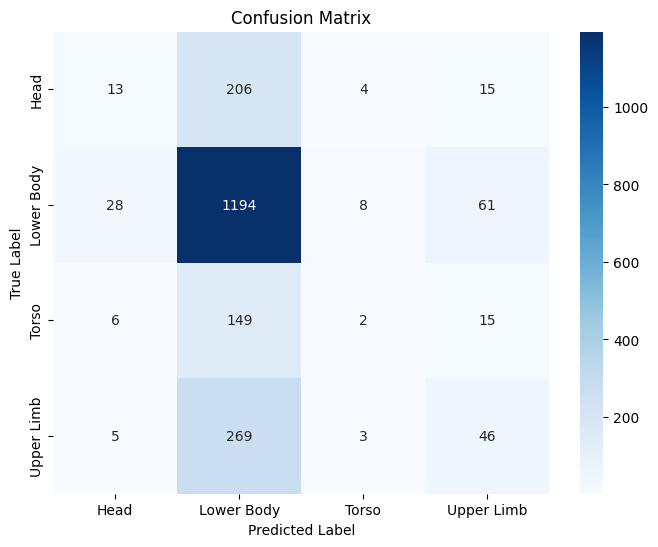

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix
conf_matrix = confusion_matrix(y_encoded, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
# Get feature importance scores
feature_importance = model.feature_importances_

# Get feature names
num_feature_names = numerical_features
cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = list(num_feature_names) + list(cat_feature_names)

# Create a DataFrame for feature importance
feature_importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': feature_importance
}).sort_values(by='Importance', ascending=False)

# Display feature importance scores
feature_importance_df

,Feature,Importance
2,Weight,0.401906
1,Height_cm,0.187659
0,Seasons Played,0.176849
8,Position_QB,0.137238
12,Position_WR,0.021454
9,Position_RB,0.015249
7,Position_LB,0.015043
3,Position_CB,0.013342
11,Position_TE,0.012743
10,Position_S,0.012030


## Weighted Cross-entropy

Cross-validated Accuracy: 0.33 ± 0.03
AUC-ROC Score: 0.547

Classification Report:
              precision    recall  f1-score   support

        Head       0.18      0.35      0.24       238
  Lower Body       0.69      0.35      0.46      1291
       Torso       0.08      0.22      0.11       172
  Upper Limb       0.23      0.30      0.26       323

    accuracy                           0.33      2024
   macro avg       0.30      0.30      0.27      2024
weighted avg       0.51      0.33      0.37      2024



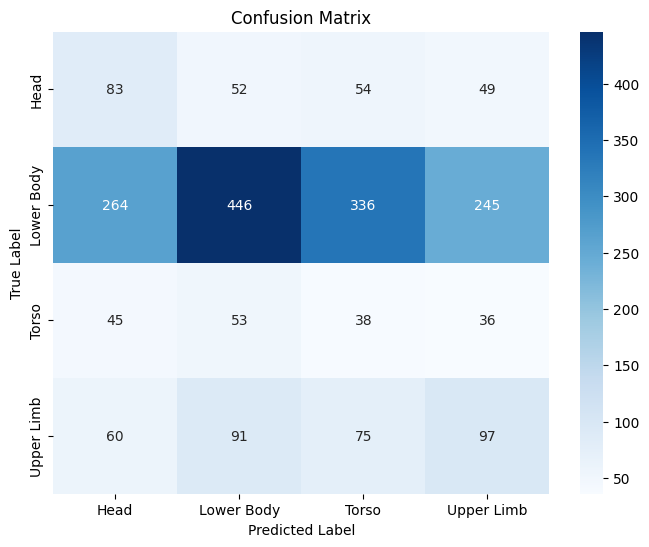

In [ ]:
import pandas as pd
import re
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_sample_weight
import numpy as np

# Load dataset
file_path = "players_data.csv"
df = pd.read_csv(file_path)

df.rename(columns=lambda x: x.strip(), inplace=True)

# Consolidated injury groups
injury_mapping = {
    "Lower Body": ["Knee", "ACL", "MCL", "Patella", "Meniscus", "Calf", "Hamstring", "Quadriceps", "Thigh", "Leg",
                   "Inguinal", "Ankle", "Toe", "Foot", "Achilles", "Heel", "Lisfranc"],
    "Head": ["Concussion", "Head", "Neck", "Cervical"],
    "Upper Limb": ["Shoulder", "Rotator", "AC", "Elbow", "Forearm", "Bicep", "Triceps", "Arm", "Finger", "Wrist", "Hand"],
    "Torso": ["Chest", "Back", "Spine", "Abdomen"]
}

def categorize_injury(injury_text):
    if pd.isna(injury_text):
        return "Other"
    injury_text = str(injury_text).lower()
    for category, keywords in injury_mapping.items():
        if any(re.search(rf'\b{kw.lower()}s?\b', injury_text) for kw in keywords):
            return category
    return "Other"

df['InjuryGroup'] = df['Injury Type'].apply(categorize_injury)

df_filtered = df[df['InjuryGroup'].isin(injury_mapping.keys())].copy()

# Height conversion
def convert_height(height_str):
    try:
        feet, inches = re.findall(r'\d+', str(height_str))
        return (int(feet) * 12 + int(inches)) * 2.54
    except:
        return None

df_filtered['Height_cm'] = df_filtered['Height'].apply(convert_height)

# Feature selection
numerical_features = ['Seasons Played', 'Height_cm', 'Weight']
categorical_features = ['Position']

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Label encode target variable
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df_filtered['InjuryGroup'])

# Compute sample weights for imbalanced classes
sample_weights = compute_sample_weight(class_weight="balanced", y=y_encoded)

# Transform features
X = preprocessor.fit_transform(df_filtered)

# StratifiedKFold setup
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Initialize model
model = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)

# Manual cross-validation
scores = []
y_true, y_pred, y_proba_list = [], [], []

for train_idx, test_idx in cv.split(X, y_encoded):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]
    weights_train = sample_weights[train_idx]

    model.fit(X_train, y_train, sample_weight=weights_train)

    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)

    scores.append(model.score(X_test, y_test))
    y_true.extend(y_test)
    y_pred.extend(y_test_pred)
    y_proba_list.extend(y_test_proba)

# Convert lists to arrays
y_pred = np.array(y_pred)
y_proba = np.array(y_proba_list)

# Compute AUC-ROC
auc_score = roc_auc_score(pd.get_dummies(y_true), y_proba, multi_class='ovr')

# Classification report
classification_rep = classification_report(y_true, y_pred, target_names=label_encoder.classes_)

# Display results
print(f"Cross-validated Accuracy: {np.mean(scores):.2f} ± {np.std(scores):.2f}")
print(f"AUC-ROC Score: {auc_score:.3f}")
print("\nClassification Report:")
print(classification_rep)

# Train model to extract feature importance
model.fit(X, y_encoded, sample_weight=sample_weights)

# Compute confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


## Sampling

## Gradent Boosting

Cross-validated Accuracy: 0.37 ± 0.05
AUC-ROC Score: 0.604

Classification Report:
              precision    recall  f1-score   support

        Head       0.38      0.38      0.38       250
  Lower Body       0.34      0.33      0.34       250
       Torso       0.39      0.44      0.41       250
  Upper Limb       0.34      0.32      0.33       250

    accuracy                           0.37      1000
   macro avg       0.36      0.37      0.36      1000
weighted avg       0.36      0.37      0.36      1000



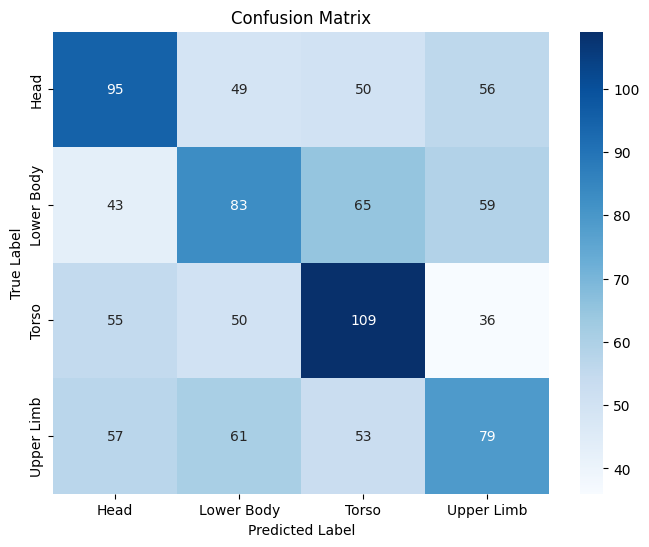

In [ ]:
import pandas as pd
import re
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_sample_weight
import numpy as np
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

# Load dataset
file_path = "players_data.csv"
df = pd.read_csv(file_path)

df.rename(columns=lambda x: x.strip(), inplace=True)

# Consolidated injury groups
injury_mapping = {
    "Lower Body": ["Knee", "ACL", "MCL", "Patella", "Meniscus", "Calf", "Hamstring", "Quadriceps", "Thigh", "Leg",
                   "Inguinal", "Ankle", "Toe", "Foot", "Achilles", "Heel", "Lisfranc"],
    "Head": ["Concussion", "Head", "Neck", "Cervical"],
    "Upper Limb": ["Shoulder", "Rotator", "AC", "Elbow", "Forearm", "Bicep", "Triceps", "Arm", "Finger", "Wrist", "Hand"],
    "Torso": ["Chest", "Back", "Spine", "Abdomen"]
}

def categorize_injury(injury_text):
    if pd.isna(injury_text):
        return "Other"
    injury_text = str(injury_text).lower()
    for category, keywords in injury_mapping.items():
        if any(re.search(rf'\b{kw.lower()}s?\b', injury_text) for kw in keywords):
            return category
    return "Other"

df['InjuryGroup'] = df['Injury Type'].apply(categorize_injury)

df_filtered = df[df['InjuryGroup'].isin(injury_mapping.keys())].copy()

# Height conversion
def convert_height(height_str):
    try:
        feet, inches = re.findall(r'\d+', str(height_str))
        return (int(feet) * 12 + int(inches)) * 2.54
    except:
        return None

df_filtered['Height_cm'] = df_filtered['Height'].apply(convert_height)

# Feature selection
numerical_features = ['Seasons Played', 'Height_cm', 'Weight']
categorical_features = ['Position']

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Label encode target variable
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df_filtered['InjuryGroup'])

# Transform features
X = preprocessor.fit_transform(df_filtered)

# Get class distribution
class_counts = np.bincount(y_encoded)

# Define exact sampling strategy: exactly 250 per class
sampling_strategy_under = {cls: 250 for cls in range(len(class_counts)) if class_counts[cls] > 250}
sampling_strategy_over = {cls: 250 for cls in range(len(class_counts)) if class_counts[cls] < 250}

# Apply undersampling for majority classes
rus = RandomUnderSampler(sampling_strategy=sampling_strategy_under, random_state=42)
X_resampled, y_resampled = rus.fit_resample(X, y_encoded)

# Apply oversampling for minority classes
ros = RandomOverSampler(sampling_strategy=sampling_strategy_over, random_state=42)
X_resampled, y_resampled = ros.fit_resample(X_resampled, y_resampled)

# StratifiedKFold setup
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Initialize model
model = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)

# Manual cross-validation
scores = []
y_true, y_pred, y_proba_list = [], [], []

for train_idx, test_idx in cv.split(X_resampled, y_resampled):
    X_train, X_test = X_resampled[train_idx], X_resampled[test_idx]
    y_train, y_test = y_resampled[train_idx], y_resampled[test_idx]

    model.fit(X_train, y_train)

    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)

    scores.append(model.score(X_test, y_test))
    y_true.extend(y_test)
    y_pred.extend(y_test_pred)
    y_proba_list.extend(y_test_proba)

# Convert lists to arrays
y_pred = np.array(y_pred)
y_proba = np.array(y_proba_list)

# Compute AUC-ROC
auc_score = roc_auc_score(pd.get_dummies(y_true), y_proba, multi_class='ovr')

# Classification report
classification_rep = classification_report(y_true, y_pred, target_names=label_encoder.classes_)

# Display results
print(f"Cross-validated Accuracy: {np.mean(scores):.2f} ± {np.std(scores):.2f}")
print(f"AUC-ROC Score: {auc_score:.3f}")
print("\nClassification Report:")
print(classification_rep)

# Train model to extract feature importance
model.fit(X_resampled, y_resampled)

# Compute confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


## Random-Forest, Logistic Regression, XGBoost


Training Random Forest...

Cross-validated Accuracy: 0.33 ± 0.05
AUC-ROC Score: 0.5856326666666667

Classification Report:
              precision    recall  f1-score   support

        Head       0.33      0.24      0.27       250
  Lower Body       0.32      0.47      0.38       250
       Torso       0.35      0.37      0.36       250
  Upper Limb       0.35      0.26      0.30       250

    accuracy                           0.33      1000
   macro avg       0.34      0.33      0.33      1000
weighted avg       0.34      0.33      0.33      1000



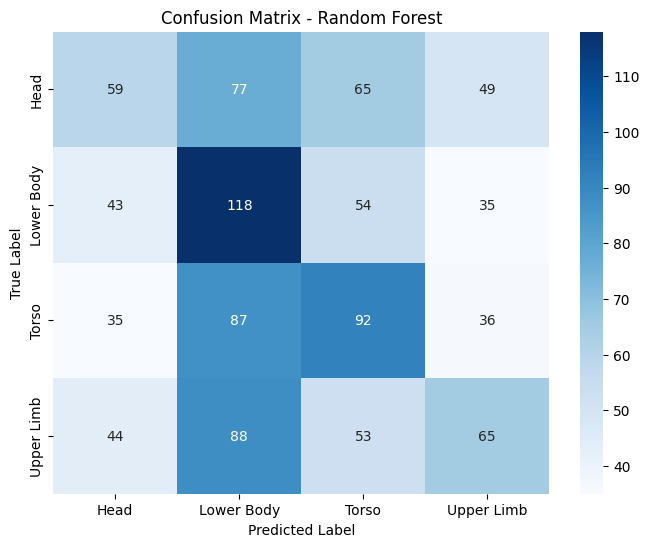


Training Logistic Regression...



/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_

Cross-validated Accuracy: 0.32 ± 0.03
AUC-ROC Score: 0.5645680000000001

Classification Report:
              precision    recall  f1-score   support

        Head       0.28      0.19      0.23       250
  Lower Body       0.31      0.52      0.39       250
       Torso       0.29      0.25      0.27       250
  Upper Limb       0.41      0.33      0.37       250

    accuracy                           0.32      1000
   macro avg       0.32      0.32      0.31      1000
weighted avg       0.32      0.32      0.31      1000



/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_

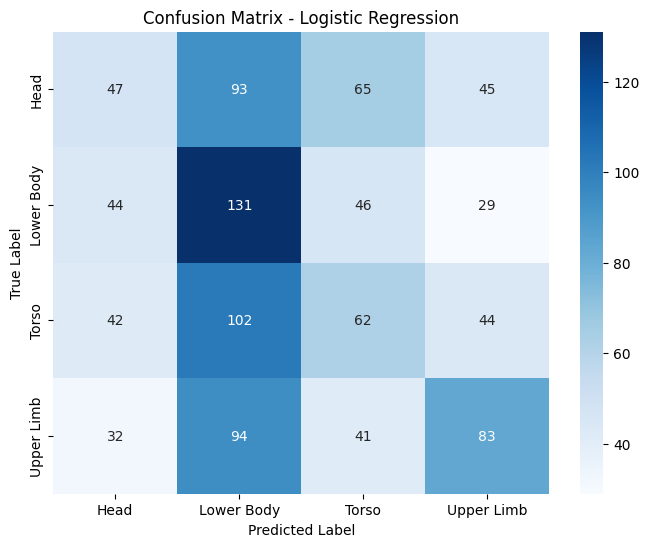


Training XGBoost...



/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/xgboost/core.py:158: UserWarning: [11:05:52] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/xgboost/core.py:158: UserWarning: [11:05:53] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/xgboost/core.py:158: UserWarning: [11:05:53] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packages/xgboost/core.py:158: UserWarning: [11:05:53] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/home/cidalab/miniconda3/envs/llm/lib/python3.12/site-packag

Cross-validated Accuracy: 0.36 ± 0.04
AUC-ROC Score: 0.6069

Classification Report:
              precision    recall  f1-score   support

        Head       0.33      0.31      0.32       250
  Lower Body       0.35      0.38      0.36       250
       Torso       0.40      0.42      0.41       250
  Upper Limb       0.35      0.32      0.33       250

    accuracy                           0.36      1000
   macro avg       0.36      0.36      0.36      1000
weighted avg       0.36      0.36      0.36      1000



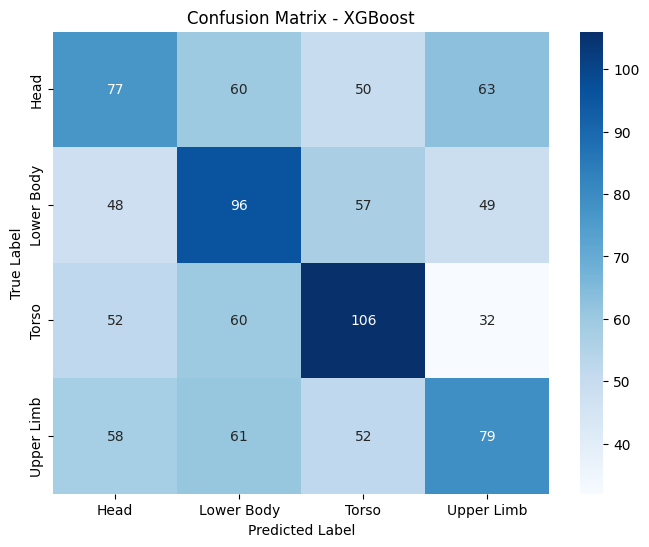

In [ ]:
import pandas as pd
import re
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_sample_weight
import numpy as np
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

# Load dataset
file_path = "players_data.csv"
df = pd.read_csv(file_path)

df.rename(columns=lambda x: x.strip(), inplace=True)

# Consolidated injury groups
injury_mapping = {
    "Lower Body": ["Knee", "ACL", "MCL", "Patella", "Meniscus", "Calf", "Hamstring", "Quadriceps", "Thigh", "Leg",
                   "Inguinal", "Ankle", "Toe", "Foot", "Achilles", "Heel", "Lisfranc"],
    "Head": ["Concussion", "Head", "Neck", "Cervical"],
    "Upper Limb": ["Shoulder", "Rotator", "AC", "Elbow", "Forearm", "Bicep", "Triceps", "Arm", "Finger", "Wrist", "Hand"],
    "Torso": ["Chest", "Back", "Spine", "Abdomen"]
}

def categorize_injury(injury_text):
    if pd.isna(injury_text):
        return "Other"
    injury_text = str(injury_text).lower()
    for category, keywords in injury_mapping.items():
        if any(re.search(rf'\b{kw.lower()}s?\b', injury_text) for kw in keywords):
            return category
    return "Other"

df['InjuryGroup'] = df['Injury Type'].apply(categorize_injury)

df_filtered = df[df['InjuryGroup'].isin(injury_mapping.keys())].copy()

# Height conversion
def convert_height(height_str):
    try:
        feet, inches = re.findall(r'\d+', str(height_str))
        return (int(feet) * 12 + int(inches)) * 2.54
    except:
        return None

df_filtered['Height_cm'] = df_filtered['Height'].apply(convert_height)

# Feature selection
numerical_features = ['Seasons Played', 'Height_cm', 'Weight']
categorical_features = ['Position']

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Label encode target variable
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df_filtered['InjuryGroup'])

# Transform features
X = preprocessor.fit_transform(df_filtered)

# Get class distribution
class_counts = np.bincount(y_encoded)

# Define exact sampling strategy: exactly 250 per class
sampling_strategy_under = {cls: 250 for cls in range(len(class_counts)) if class_counts[cls] > 250}
sampling_strategy_over = {cls: 250 for cls in range(len(class_counts)) if class_counts[cls] < 250}

# Apply undersampling for majority classes
rus = RandomUnderSampler(sampling_strategy=sampling_strategy_under, random_state=42)
X_resampled, y_resampled = rus.fit_resample(X, y_encoded)

# Apply oversampling for minority classes
ros = RandomOverSampler(sampling_strategy=sampling_strategy_over, random_state=42)
X_resampled, y_resampled = ros.fit_resample(X_resampled, y_resampled)

# StratifiedKFold setup
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Initialize models
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42, use_label_encoder=False, eval_metric='mlogloss')
}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...\n")
    scores = []
    y_true, y_pred, y_proba_list = [], [], []

    for train_idx, test_idx in cv.split(X_resampled, y_resampled):
        X_train, X_test = X_resampled[train_idx], X_resampled[test_idx]
        y_train, y_test = y_resampled[train_idx], y_resampled[test_idx]

        model.fit(X_train, y_train)

        y_test_pred = model.predict(X_test)
        y_test_proba = model.predict_proba(X_test) if hasattr(model, 'predict_proba') else None

        scores.append(model.score(X_test, y_test))
        y_true.extend(y_test)
        y_pred.extend(y_test_pred)
        if y_test_proba is not None:
            y_proba_list.extend(y_test_proba)

    # Convert lists to arrays
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba_list) if y_proba_list else None

    # Compute AUC-ROC if applicable
    auc_score = roc_auc_score(pd.get_dummies(y_true), y_proba, multi_class='ovr') if y_proba is not None else "N/A"

    # Classification report
    classification_rep = classification_report(y_true, y_pred, target_names=label_encoder.classes_)

    # Display results
    print(f"Cross-validated Accuracy: {np.mean(scores):.2f} ± {np.std(scores):.2f}")
    print(f"AUC-ROC Score: {auc_score}")
    print("\nClassification Report:")
    print(classification_rep)

    # Compute confusion matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Plot confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()

## ikowsar@tnstate.edu